## Kiểm tra thư viện

In [1]:
import numpy, pandas, matplotlib, sklearn
print("numpy       ", numpy.__version__)
print("pandas      ", pandas.__version__)
print("matplotlib ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)


numpy        2.1.3
pandas       3.1.1
matplotlib  3.10.3
scikit-learn 1.7.0


## 1 - Đọc dữ liệu bằng Pandas

In [ ]:
# -*- coding: utf-8 -*-


import pandas as pd

# Đọc tệp CSV thành một bảng. Tên df là viết tắt quen dùng của data frame.
df = pd.read_csv("data/gia_nha.csv")

print("Kich thuoc bang (so dong, so cot):", df.shape)
print()

print("Nam dong dau tien:")
print(df.head())
print()

print("Ten cac cot:", list(df.columns))
print()

print("Thong ke nhanh cot dien_tich va cot gia:")
print(df[["dien_tich", "gia"]].describe().round(2))
print()

print("So o bi thieu trong tung cot:")
print(df.isna().sum())


Kich thuoc bang (so dong, so cot): (60, 4)

Nam dong dau tien:
   dien_tich  so_phong  tuoi_nha   gia
0       35.5         1        18  3.00
1       37.6         2         7  3.87
2       49.4         2        20  4.25
3       49.0         2        16  4.60
4       49.9         1        12  3.99

Ten cac cot: ['dien_tich', 'so_phong', 'tuoi_nha', 'gia']

Thong ke nhanh cot dien_tich va cot gia:
       dien_tich    gia
count      60.00  60.00
mean       77.73   6.49
std        20.22   1.64
min        35.50   3.00
25%        63.02   5.16
50%        75.10   6.40
75%        91.88   7.70
max       117.50   9.74

So o bi thieu trong tung cot:
dien_tich    0
so_phong     0
tuoi_nha     0
gia          0
dtype: int64


## 2 - Tính MSE của hai đường thẳng

In [ ]:
# -*- coding: utf-8 -*-


import pandas as pd

df = pd.read_csv("data/gia_nha.csv")

# Lấy 5 căn trải đều từ nhỏ nhất tới lớn nhất, không lấy 5 căn đầu bảng
# vì chúng có diện tích gần bằng nhau nên nhìn không rõ.
nho = df.iloc[[0, 14, 29, 44, 59]]

x = nho["dien_tich"].to_numpy()
y = nho["gia"].to_numpy()


def mse(w, b):
    """Sai số trung bình bình phương của đường thẳng y = w*x + b."""
    y_du_doan = w * x + b
    sai_so = y - y_du_doan
    return (sai_so ** 2).mean()


print("Nam can duoc chon:")
for i in range(5):
    print(f" {x[i]:6.1f} m2     ->   {y[i]:5.2f} ty")
print()

for w, b in [(0.05, 1.5), (0.08, 0.5)]:
    print(f"Duong thang y = {w} * x + {b}")
    for i in range(5):
        du_doan = w * x[i] + b
        sai_so = y[i] - du_doan
        print(f" x = {x[i]:6.1f}    that = {y[i]:5.2f}"
              f"   du doan = {du_doan:5.2f}   sai so = {sai_so:+6.2f}")
    print(f" MSE = {mse(w, b):.4f}")
    print()

print("Duong nao co MSE nho hon thi duong do khop du lieu tot hon.")


Nam can duoc chon:
   35.5 m2     ->    3.00 ty
   61.3 m2     ->    4.56 ty
   74.2 m2     ->    7.17 ty
   91.3 m2     ->    7.83 ty
  115.9 m2     ->    9.01 ty

Duong thang y = 0.05 * x + 1.5
 x =   35.5    that =  3.00   du doan =  3.28   sai so =  -0.28
 x =   61.3    that =  4.56   du doan =  4.56   sai so =  -0.00
 x =   74.2    that =  7.17   du doan =  5.21   sai so =  +1.96
 x =   91.3    that =  7.83   du doan =  6.07   sai so =  +1.76
 x =  115.9    that =  9.01   du doan =  7.30   sai so =  +1.71
 MSE = 1.9947

Duong thang y = 0.08 * x + 0.5
 x =   35.5    that =  3.00   du doan =  3.34   sai so =  -0.34
 x =   61.3    that =  4.56   du doan =  5.40   sai so =  -0.84
 x =   74.2    that =  7.17   du doan =  6.44   sai so =  +0.73
 x =   91.3    that =  7.83   du doan =  7.80   sai so =  +0.03
 x =  115.9    that =  9.01   du doan =  9.77   sai so =  -0.76
 MSE = 0.3896

Duong nao co MSE nho hon thi duong do khop du lieu tot hon.


## 3 - Tính hệ số w, b bằng công thức

In [ ]:
# -*- coding: utf-8 -*-

import numpy as np
import pandas as pd

df = pd.read_csv("data/gia_nha.csv")
x = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()

x_tb = x.mean()
y_tb = y.mean()

# Công thức bình phương tối thiểu cho đường thẳng một biến
tu_so = ((x - x_tb) * (y - y_tb)).sum()
mau_so = ((x - x_tb) ** 2).sum()

w = tu_so / mau_so
b = y_tb - w * x_tb

print(f"Trung binh dien tich : {x_tb:.4f}")
print(f"Trung binh gia       : {y_tb:.4f}")
print(f"Tu so                : {tu_so:.4f}")
print(f"Mau so               : {mau_so:.4f}")
print()
print(f"He so goc      w = {w:.6f}")
print(f"He so chan     b = {b:.6f}")
print()
print(f"Mo hinh: gia = {w:.4f} * dien_tich + {b:.4f}")
print()

y_du_doan = w * x + b
mse = ((y - y_du_doan) ** 2).mean()
print(f"MSE tren toan bo 60 can: {mse:.4f}")

# Dự đoán cho một căn 80 m2
print(f"Can 80 m2 duoc du doan: {w * 80 + b:.3f} ty dong")


Trung binh dien tich : 77.7317
Trung binh gia       : 6.4933
Tu so                : 1890.2297
Mau so               : 24120.2898

He so goc      w = 0.078367
He so chan     b = 0.401752

Mo hinh: gia = 0.0784 * dien_tich + 0.4018

MSE tren toan bo 60 can: 0.1790
Can 80 m2 duoc du doan: 6.671 ty dong


## 4 - Hồi quy tuyến tính bằng Scikit-learn

In [ ]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.linear_model import LinearRegression

df = pd.read_csv("data/gia_nha.csv")

# X phải là bảng hai chiều, y là dãy một chiều.
# Chú ý X viết hai cặp ngoặc vuông, còn y chỉ một cặp.
X = df[["dien_tich"]]
y = df["gia"]

mo_hinh = LinearRegression()
mo_hinh.fit(X, y)

print("He so goc w =", round(float(mo_hinh.coef_[0]), 6))
print("He so chan b =", round(float(mo_hinh.intercept_), 6))
print()

# So sánh với kết quả tính tay ở bước 3
print("Ket qua tinh tay o buoc 3: w = 0.078367, b = 0.401752")
print()

can_moi = pd.DataFrame({"dien_tich": [80.0, 100.0]})
du_doan = mo_hinh.predict(can_moi)
for dt, gia in zip(can_moi["dien_tich"], du_doan):
    print(f"Can {dt:.0f} m2 -> du doan {gia:.3f} ty dong")


He so goc w = 0.078367
He so chan b = 0.401752

Ket qua tinh tay o buoc 3: w = 0.078367, b = 0.401752

Can 80 m2 -> du doan 6.671 ty dong
Can 100 m2 -> du doan 8.238 ty dong


## 5 - Đánh giá mô hình bằng MAE, MSE, RMSE và R²

In [ ]:
# -*- coding: utf-8 -*-

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# 80 phần trăm để học, 20 phần trăm để kiểm tra.
# random_state cố định để lần nào chia cũng ra đúng một cách chia.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("So can de hoc     :", len(X_train))
print("So can de kiem tra:", len(X_test))
print()

mo_hinh = LinearRegression()
mo_hinh.fit(X_train, y_train)  # chỉ học trên tập học

y_pred = mo_hinh.predict(X_test)  # chấm điểm trên tập kiểm tra

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE = {mae:.4f} ty dong")
print(f"MSE = {mse:.4f}")
print(f"RMSE = {rmse:.4f} ty dong")
print(f"R2   = {r2:.4f}")
print()

print("Mot vai can trong tap kiem tra:")
for dt, that, du_doan in list(zip(X_test["dien_tich"], y_test, y_pred))[:5]:
    print(f" {dt:6.1f} m2    that = {that:5.2f}   du doan = {du_doan:5.2f}"
          f"   sai so = {that - du_doan:+5.2f}")


So can de hoc     : 48
So can de kiem tra: 12

MAE = 0.2578 ty dong
MSE = 0.1392
RMSE = 0.3730 ty dong
R2   = 0.9622

Mot vai can trong tap kiem tra:
   35.5 m2    that =  3.00   du doan =  3.22   sai so = -0.22
   50.4 m2    that =  4.24   du doan =  4.38   sai so = -0.14
   82.5 m2    that =  7.28   du doan =  6.88   sai so = +0.40
   93.6 m2    that =  7.63   du doan =  7.74   sai so = -0.11
   59.6 m2    that =  5.14   du doan =  5.09   sai so = +0.05


## 6 - Gradient Descent

In [ ]:
# -*- coding: utf-8 -*-


import numpy as np
import pandas as pd

df = pd.read_csv("data/gia_nha.csv")
x_goc = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()

# Đưa diện tích về thang đo nhỏ quanh số 0. Thiếu bước này thuật toán sẽ vỡ.
x_tb = x_goc.mean()
x_do_lech = x_goc.std()
x = (x_goc - x_tb) / x_do_lech

w, b = 0.0, 0.0       # bắt đầu từ một đường thẳng nằm ngang đi qua gốc
toc_do_hoc = 0.1      # mỗi vòng lặp đi một bước dài bằng 0.1 lần độ dốc
so_vong = 200
n = len(x)

print("Vong    w        b        MSE")
for vong in range(1, so_vong + 1):
    y_du_doan = w * x + b
    # Chú ý: đây là dự đoán trừ giá thật, tức sai số của Mục 4 đảo dấu.
    # Hai công thức độ dốc bên dưới viết theo đúng chiều này, đừng đổi dấu.
    chenh_lech = y_du_doan - y

    # Độ dốc của MSE theo w và theo b
    grad_w = (2 / n) * (chenh_lech * x).sum()
    grad_b = (2 / n) * chenh_lech.sum()

    # Đi ngược hướng dốc thì sai số giảm
    w -= toc_do_hoc * grad_w
    b -= toc_do_hoc * grad_b

    if vong in (1, 2, 5, 10, 25, 50, 100, 200):
        # Tính lại MSE bằng w và b VỪA cập nhật, để ba con số trên cùng một
        # dòng bảng đều thuộc về cùng một thời điểm.
        mse = (((w * x + b) - y) ** 2).mean()
        print(f"{vong:4d} {w:7.4f} {b:7.4f} {mse:8.4f}")

print()
# Đổi w và b về lại thang đo mét vuông ban đầu
w_goc = w / x_do_lech
b_goc = b - w * x_tb / x_do_lech
print("Sau khi doi ve thang do met vuong:")
print(f" w = {w_goc:.6f}")
print(f" b = {b_goc:.6f}")
print("So voi cong thuc o buoc 3: w = 0.078367, b = 0.401752")


Vong    w        b        MSE
   1  0.3143  1.2987  28.7437
   2  0.5657  2.3376  18.4604
   5  1.0564  4.3656   4.9714
  10  1.4025  5.7961   0.6936
  25  1.5653  6.4688   0.1797
  50  1.5712  6.4932   0.1790
 100  1.5713  6.4933   0.1790
 200  1.5713  6.4933   0.1790

Sau khi doi ve thang do met vuong:
 w = 0.078367
 b = 0.401752
So voi cong thuc o buoc 3: w = 0.078367, b = 0.401752


## 7 - Hồi quy tuyến tính nhiều biến

In [ ]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/gia_nha.csv")
y = df["gia"]

# Chỉ đổi đúng một chỗ: danh sách cột đưa vào X
X_mot = df[["dien_tich"]]
X_ba = df[["dien_tich", "so_phong", "tuoi_nha"]]

for ten, X in [("Mot bien ", X_mot), ("Ba bien       ", X_ba)]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    mo_hinh = LinearRegression()
    mo_hinh.fit(X_train, y_train)
    r2 = r2_score(y_test, mo_hinh.predict(X_test))
    print(f"{ten}: R2 tren tap kiem tra = {r2:.4f}")

print()

# Xem kỹ các hệ số của mô hình ba biến
X_train, X_test, y_train, y_test = train_test_split(
    X_ba, y, test_size=0.2, random_state=42
)
mo_hinh = LinearRegression()
mo_hinh.fit(X_train, y_train)

print("He so cua tung bien:")
for ten_cot, he_so in zip(X_ba.columns, mo_hinh.coef_):
    print(f" {ten_cot:12s} {he_so:+.4f}")
print(f" {'he so chan':12s} {mo_hinh.intercept_:+.4f}")


Mot bien : R2 tren tap kiem tra = 0.9622
Ba bien       : R2 tren tap kiem tra = 0.9761

He so cua tung bien:
 dien_tich    +0.0701
 so_phong     +0.3042
 tuoi_nha     -0.0295
 he so chan   +0.6917


# Bài tập

## Bài tập 1 - Lọc căn hộ có diện tích lớn hơn 100 m²

In [9]:
import pandas as pd

df = pd.read_csv("data/gia_nha.csv")
nhom_lon = df[df["dien_tich"] > 100]

print("So can co dien tich tren 100 m2:", len(nhom_lon))
print(f"Gia trung binh cua nhom: {nhom_lon['gia'].mean():.4f} ty dong")


So can co dien tich tren 100 m2: 10
Gia trung binh cua nhom: 8.9620 ty dong


- Sử dụng điều kiện lọc để lấy đúng nhóm căn trên 100 m²
- Hàm `mean()` tính giá trung bình của riêng nhóm này

## Bài tập 2 - Biểu đồ giá theo số phòng

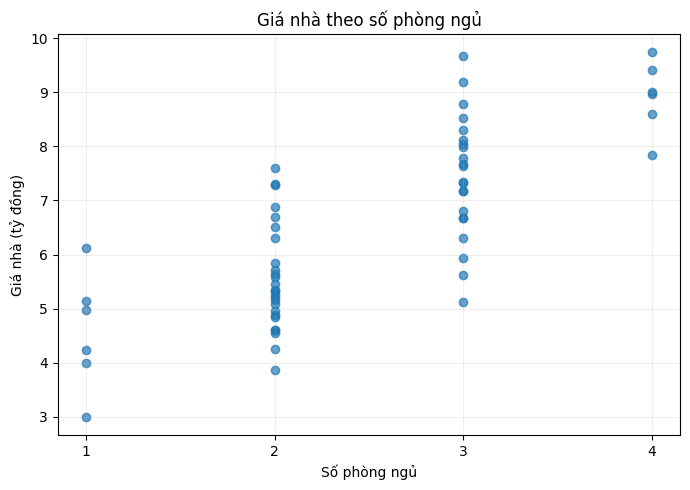

Gia trung binh theo so phong:
so_phong
1    4.578
2    5.567
3    7.447
4    8.923
Name: gia, dtype: float64
Nhan xet: Nhom nhieu phong hon co gia trung binh cao hon nhom it phong.


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/gia_nha.csv")

plt.figure(figsize=(7, 5))
plt.scatter(df["so_phong"], df["gia"], alpha=0.7)
plt.xlabel("Số phòng ngủ")
plt.ylabel("Giá nhà (tỷ đồng)")
plt.title("Giá nhà theo số phòng ngủ")
plt.xticks(sorted(df["so_phong"].unique()))
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("bai2.png", dpi=150)
plt.show()

# Tính giá trung bình ở từng nhóm phòng để nhận xét có căn cứ.
trung_binh = df.groupby("so_phong")["gia"].mean()
print("Gia trung binh theo so phong:")
print(trung_binh.round(3))
if trung_binh.iloc[-1] > trung_binh.iloc[0]:
    print("Nhan xet: Nhom nhieu phong hon co gia trung binh cao hon nhom it phong.")
else:
    print("Nhan xet: So phong nhieu hon khong nhat thiet co gia trung binh cao hon.")


- Mỗi điểm thể hiện số phòng và giá của một căn hộ
- Xem giá trung bình theo số phòng để nhận xét xu hướng thay vì chỉ nhìn một điểm

## Bài tập 3 - Hồi quy theo tuổi nhà

He so goc w = -0.037858
He so chan b = 6.983593
Nhan xet: Tuoi nha tang thi gia du doan co xu huong giam.


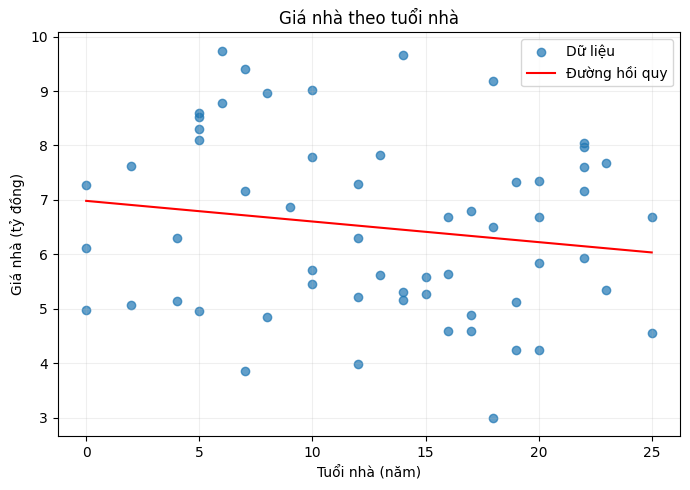

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/gia_nha.csv")
x = df["tuoi_nha"].to_numpy()
y = df["gia"].to_numpy()

x_tb = x.mean()
y_tb = y.mean()
w = ((x - x_tb) * (y - y_tb)).sum() / ((x - x_tb) ** 2).sum()
b = y_tb - w * x_tb

print(f"He so goc w = {w:.6f}")
print(f"He so chan b = {b:.6f}")
if w < 0:
    print("Nhan xet: Tuoi nha tang thi gia du doan co xu huong giam.")
else:
    print("Nhan xet: Du lieu nay chua cho thay he so goc am.")

# Phần mở rộng: vẽ hình để xem quan hệ này có thật sự tuyến tính không.
plt.figure(figsize=(7, 5))
plt.scatter(x, y, alpha=0.7, label="Dữ liệu")
plt.plot(np.sort(x), w * np.sort(x) + b, color="red", label="Đường hồi quy")
plt.xlabel("Tuổi nhà (năm)")
plt.ylabel("Giá nhà (tỷ đồng)")
plt.title("Giá nhà theo tuổi nhà")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


- Hệ số `w` cho biết giá dự đoán thay đổi bao nhiêu khi tuổi nhà tăng một năm
- Hệ số âm cho thấy nhà cũ hơn thường có giá thấp hơn trong bộ dữ liệu này
- Cần nhìn biểu đồ để xem các điểm có nằm gần đường hồi quy hay không

## Bài tập 4 - Thêm số phòng vào mô hình

In [12]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/gia_nha.csv")
y = df["gia"]

def danh_gia(cac_cot):
    X = df[cac_cot]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    mo_hinh = LinearRegression()
    mo_hinh.fit(X_train, y_train)
    return r2_score(y_test, mo_hinh.predict(X_test))

r2_mot_bien = danh_gia(["dien_tich"])
r2_hai_bien = danh_gia(["dien_tich", "so_phong"])

print(f"R2 mot bien  = {r2_mot_bien:.4f}")
print(f"R2 hai bien = {r2_hai_bien:.4f}")
print(f"Moc so sanh trong PDF = 0.9622")
print(f"Chenh lech R2 = {r2_hai_bien - r2_mot_bien:+.4f}")
if r2_hai_bien > r2_mot_bien:
    print("Nhan xet: Them so phong giup mo hinh du doan tot hon tren tap kiem tra.")
else:
    print("Nhan xet: Them so phong chua giup mo hinh cai thien tren tap kiem tra.")


R2 mot bien  = 0.9622
R2 hai bien = 0.9698
Moc so sanh trong PDF = 0.9622
Chenh lech R2 = +0.0075
Nhan xet: Them so phong giup mo hinh du doan tot hon tren tap kiem tra.


- So sánh hai mô hình trên cùng cách chia dữ liệu `test_size=0.2` và `random_state=42`
- Nếu R² tăng thì thêm số phòng có ích trong lần kiểm tra này

## Bài tập 5 - Thử tốc độ học của Gradient Descent

In [13]:
import numpy as np
import pandas as pd

df = pd.read_csv("data/gia_nha.csv")
x_goc = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()
x = (x_goc - x_goc.mean()) / x_goc.std()
n = len(x)

def thu_toc_do_hoc(toc_do_hoc, so_vong=200):
    w, b = 0.0, 0.0
    for vong in range(1, so_vong + 1):
        chenh_lech = (w * x + b) - y
        grad_w = (2 / n) * (chenh_lech * x).sum()
        grad_b = (2 / n) * chenh_lech.sum()
        w -= toc_do_hoc * grad_w
        b -= toc_do_hoc * grad_b
    mse = (((w * x + b) - y) ** 2).mean()
    return mse

for toc_do_hoc in [0.001, 1.02]:
    mse = thu_toc_do_hoc(toc_do_hoc)
    print(f"Toc do hoc {toc_do_hoc:<5}: MSE vong 200 = {mse:.6g}")

# Phần làm thêm của đề: thử 0.5, 0.9 và quan sát ranh giới hội tụ.
for toc_do_hoc in [0.1, 0.5, 0.9, 0.99, 1.0]:
    mse = thu_toc_do_hoc(toc_do_hoc)
    print(f"Kiem tra them {toc_do_hoc:<5}: MSE = {mse:.6g}")

print("Nhan xet: Toc do qua nho hoi tu cham, qua lon co the lam MSE tang.")


Toc do hoc 0.001: MSE vong 200 = 20.2175
Toc do hoc 1.02 : MSE vong 200 = 2.90392e+08
Kiem tra them 0.1  : MSE = 0.179025
Kiem tra them 0.5  : MSE = 0.179025
Kiem tra them 0.9  : MSE = 0.179025
Kiem tra them 0.99 : MSE = 0.192831
Kiem tra them 1.0  : MSE = 44.8113
Nhan xet: Toc do qua nho hoi tu cham, qua lon co the lam MSE tang.


- Tốc độ học `0.001` nhỏ nên sau 200 vòng mô hình có thể chưa tới điểm tốt nhất
- Tốc độ học `1.02` lớn nên các bước cập nhật có thể làm sai số tăng mạnh
- MSE ở vòng 200 giúp so sánh trực tiếp hai tốc độ

## Bài tập 6 - Hàm dự đoán giá có cảnh báo

In [14]:
# Dùng đúng hệ số và khoảng diện tích đã được cho trong PDF.
w = 0.078367
b = 0.401752

def du_doan_gia(dien_tich):
    if dien_tich < 35.5 or dien_tich > 117.5:
        print(f"Canh bao: {dien_tich} m2 nam ngoai khoang du lieu 35.5-117.5 m2.")
    return w * dien_tich + b

for dien_tich in [60, 80, 200]:
    gia_du_doan = du_doan_gia(dien_tich)
    print(f"Can {dien_tich} m2: gia du doan = {gia_du_doan:.3f} ty dong")


Can 60 m2: gia du doan = 5.104 ty dong
Can 80 m2: gia du doan = 6.671 ty dong
Canh bao: 200 m2 nam ngoai khoang du lieu 35.5-117.5 m2.
Can 200 m2: gia du doan = 16.075 ty dong


- Hàm trả về giá dự đoán bằng `w * dien_tich + b`
- Căn 200 m² nằm ngoài khoảng đã học nên cần cảnh báo
- Căn 80 m² có giá dự đoán khoảng 6.671 tỷ đồng theo hệ số của PDF